In [1]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from models.model import *

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image

from utils import get_device, get_dataset, heatmap, project

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print("Device:", device, torch.cuda.get_device_name(0))
else:
    print("Device:", device)

Device: cuda:0 NVIDIA GeForce RTX 3050 Ti Laptop GPU


In [4]:
# single playing card dataset has 17 concepts
# multi card dataset has 52 concepts



N_CONCEPT = 52
N_CLASSES = 6
NUM_IMG_OUTPUT = 1
USE_SIG = True
val_loader = load_data("./dataset/playing-cards/splits/three_card_class/val.pkl", 16, num_concepts=N_CONCEPT, dataset_root="./dataset/playing-cards/", return_orig=True, shuffle=True)

concept_index_to_string = IndexToString("./dataset/playing-cards/splits/three_card_poker_card_class/concepts.txt")
class_index_to_string = IndexToString("./dataset/playing-cards/splits/three_card_poker_card_class/classes.txt")

XtoCtoY = End2EndModel(num_classes=N_CLASSES, num_concepts=N_CONCEPT, num_images_per_output=NUM_IMG_OUTPUT, use_sigmoid=USE_SIG, use_modulelist=False)
XtoCtoY.load_state_dict(torch.load("./saves/XtoCtoY_converted.pth", map_location=torch.device('cpu')))
XtoCtoY.to(device)
XtoCtoY.eval()

print("model loaded")

model loaded


## Show true concepts and classification + predicted concepts and classification

True image size (channels, width, height): torch.Size([3, 299, 299])
True  image concepts: tensor([0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])


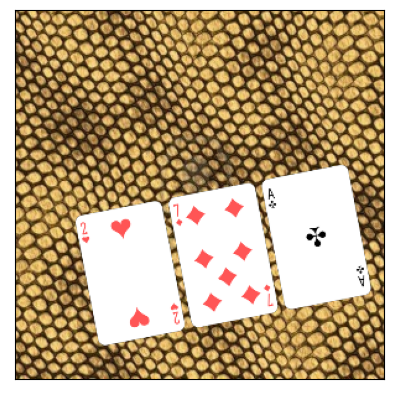

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


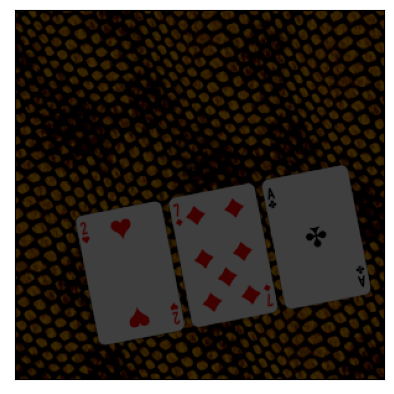

In [5]:
imageId = 7

images, labels, concepts, original_imgs = next(iter(val_loader))
image, label = images[imageId].to(device), labels[imageId].to(device)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts[imageId])

plt.xticks([])
plt.yticks([])
plt.imshow(original_imgs[imageId].squeeze().permute(1, 2, 0))
plt.show()

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

In [6]:
image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
prediction = XtoCtoY(image)

concept_out = prediction[0]
task_out = prediction[1]

_, task_out = task_out.max(1)

pred_concepts_readable = torch.nn.Sigmoid()(concept_out)
print("Predicted concepts:", pred_concepts_readable)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")
        
print("Class out:", class_index_to_string(task_out.item()))

Predicted concepts: tensor([[    0.0002,     0.0000,     0.0000,     0.0000,     0.4491,     0.0185,
             0.7359,     0.0006,     0.0004,     0.0005,     0.0036,     0.0000,
             0.0000,     0.0003,     0.0007,     0.0000,     0.0000,     0.0029,
             0.0012,     0.0000,     0.0004,     0.0410,     0.0346,     0.0000,
             0.0011,     0.7987,     0.0444,     0.0002,     0.0139,     0.0321,
             0.0005,     0.0004,     0.0002,     0.0000,     0.0001,     0.0000,
             0.7483,     0.0111,     0.4598,     0.0015,     0.0001,     0.0000,
             0.0001,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0004,     0.0000]], device='cuda:0',
       grad_fn=<SigmoidBackward0>)
id: 6, concept name: 2H, sig value: 0.735898494720459
id: 25, concept name: 7D, sig value: 0.798665463924408
id: 36, concept name: AC, sig value: 0.7483195066452026
Class out: high_card


# multi card input model


In [3]:
# single playing card dataset has 17 concepts
# multi card dataset has 52 concepts



N_CONCEPT = 52
N_CLASSES = 6
val_loader = load_data("./dataset/individual_three_card_poker/val.pkl", 16, num_concepts=N_CONCEPT, dataset_root="./dataset/individual_three_card_poker", return_orig=True, multi_image=True, shuffle=True)

concept_index_to_string = IndexToString("./dataset/individual_three_card_poker/card_classes.txt")
class_index_to_string = IndexToString("./dataset/individual_three_card_poker/hand_classes.txt")

XtoCtoY = End2EndModel(num_classes=N_CLASSES, num_concepts=N_CONCEPT, num_images_per_output=3, use_sigmoid=True, use_modulelist=False)
XtoCtoY.load_state_dict(torch.load("./saves/XtoCtoY_converted.pth", map_location=torch.device('cpu')))
XtoCtoY.to(device)
XtoCtoY.eval()

print("model loaded")

model loaded


True image size (channels, width, height): torch.Size([3, 3, 299, 299])
True  image concepts: tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])


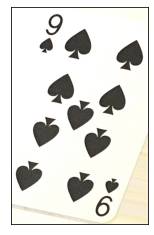

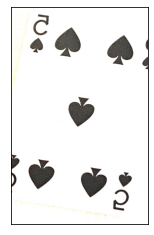

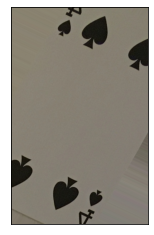

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


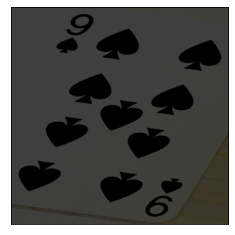

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


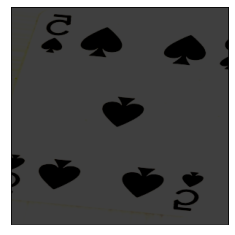

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


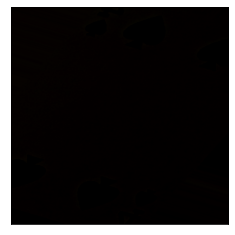

In [9]:
imageId = 7

images, labels, concepts, original_imgs = next(iter(val_loader))
image, label = images[imageId].to(device), labels[imageId].to(device)

concepts[imageId] = concepts[imageId].view(3, -1)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts[imageId])


for i in range(images.size(1)):

    plt.xticks([])
    plt.yticks([])
    plt.imshow(original_imgs[imageId][i, :, :, :].squeeze().permute(1, 2, 0))
    plt.show()

for i in range(images.size(1)):

    plt.xticks([])
    plt.yticks([])
    plt.imshow(images[imageId][i, :, :, :].squeeze().permute(1, 2, 0))
    plt.show()

In [10]:
image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
prediction = XtoCtoY(image)

concept_out = prediction[0]
task_out = prediction[1]

_, task_out = task_out.max(1)

concept_out = concept_out.view(3, -1)

for i in range(concept_out.size(0)):
    pred_concepts_readable = torch.nn.Sigmoid()(concept_out[i])
    print("Predicted concepts:", pred_concepts_readable)

    # print concept as string if prediction is >= 0.5
    for idx, i in enumerate(pred_concepts_readable):
        if i.item() >= 0.5:
            print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")
        
print("Class out:", class_index_to_string(task_out.item()))

Predicted concepts: tensor([    0.0000,     0.0000,     0.0000,     0.0006,     0.0000,     0.0000,
            0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
            0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
            0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
            0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
            0.0000,     0.0007,     0.0008,     0.0000,     0.0000,     0.9306,
            0.0000,     0.0000,     0.0000,     0.0000,     0.0001,     0.0000,
            0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0001,
            0.0000,     0.0000,     0.0000,     0.0005],
       grad_fn=<SigmoidBackward0>)
id: 35, concept name: 9S, sig value: 0.9305792450904846
Predicted concepts: tensor([    0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
            0.0000,     0.0000,     0.0000,     0.0000,     0.0001,     0.0000,
            